# Search-01 : Espaces d'etats et formalisation de problemes (Rust)

**Navigation** : [<< Search-01 Python](Search-01-StateSpace.ipynb) | [Index](../README.md) | [Search-02 Uninformed Python >>](Search-02-Uninformed.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :

1. Traduire le formalisme des espaces d'etats — le 5-uplet (S, s0, A, T, G) — en un **trait Rust** generique
2. Mesurer la taille d'un espace d'etats et comprendre l'explosion factorielle (en `u128`)
3. Resoudre un probleme de plus court chemin avec l'organe natif **`petgraph`** (Dijkstra) et reconstruire l'itineraire
4. Calculer une centralite d'intermediabilite (algorithme de Brandes) et la comparer au jumeau Python (`networkx`)
5. Reconnaître les idiomes du kernel **evcxr** : cellules autonomes, `:dep` en tete, types opaques dans un bloc

**Duree estimee** : ~25 min | **Prerequis** : [Search-01 Python](Search-01-StateSpace.ipynb) | **Lien** : Voir aussi [Search-01 C#](Search-01-StateSpace-CSharp.ipynb)

***

Ce carnet est le jumeau Rust de [Search-01 Python](Search-01-StateSpace.ipynb). La theorie complete (definition formelle, exemples fondateurs, pieges classiques) vit dans le jumeau Python ; ici, l'accent est mis sur la **traduction du formalisme en Rust** et sur les organes natifs de l'ecosysteme.

**Note de parite** : le jumeau C# travaille sur un graphe de France legerement different (13 villes, 41 arcs) ; les valeurs chiffrees du present carnet sont celles du jumeau Python (11 villes, 14 aretes).

## Table des matieres

1. [L'organe : la bibliotheque standard et la crate petgraph](#1-lorgane-la-bibliotheque-standard-et-la-crate-petgraph)
2. [Le formalisme : un trait SearchProblem](#2-le-formalisme-un-trait-searchproblem)
3. [Le taquin : explosion factorielle](#3-le-taquin-explosion-factorielle)
4. [Le probleme routier : Dijkstra et centralite](#4-le-probleme-routier-dijkstra-et-centralite)
5. [Exemples guides : missionnaires-cannibales et labyrinthe](#5-exemples-guides-missionnaires-cannibales-et-labyrinthe)
6. [Exercices](#6-exercices)

## References

- Russell & Norvig, *Artificial Intelligence: A Modern Approach* (4e ed.), chapitre 3 — la formalisation (S, s0, A, T, G)
- [Crate petgraph (crates.io)](https://crates.io/crates/petgraph) — graphes et algorithmes (MIT/Apache-2.0)
- [Crate plotters (crates.io)](https://crates.io/crates/plotters) — figures (MIT)
- [evcxr — le kernel Jupyter pour Rust](https://github.com/evcxr/evcxr)
- Brandes (2001), *A Faster Algorithm for Betweenness Centrality*

## 1. L'organe : la bibliotheque standard et la crate petgraph

Le jumeau Python ecrit ses structures de donnees avec les `dict`/`set` de la bibliotheque standard et ses graphes avec `networkx`. En Rust, la bibliotheque standard fournit deja les organes de base (`Vec`, `VecDeque`, `HashSet`, `HashMap`, `BinaryHeap`), et la crate **`petgraph`** est l'organe natif des graphes.

| | Jumeau Python | Ce carnet (Rust) |
|---|---|---|
| File FIFO du BFS | `collections.deque` | `std::collections::VecDeque` |
| Ensemble des etats vus | `set` | `std::collections::HashSet` |
| Tas de priorite (Dijkstra) | `heapq` | `std::collections::BinaryHeap` (avec `Reverse`) |
| Graphe | classe maison + `networkx` | **crate `petgraph`** (l'organe) |
| Centralite | `networkx.betweenness_centrality` | algorithme de Brandes (copie pedagogique declaree) |
| Figures | `matplotlib` | crate `plotters` (feature `evcxr`) |

Les deux `:dep` ci-dessous ajoutent les dependances cargo **directement dans le kernel** — l'equivalent Rust des cellules `# pip install` (Python) ou `#r "nuget:"` (.NET). Ils sont en **tete du carnet uniquement** : un `:dep` ajoute plus bas recompile tout et efface les variables typées.

**Idiome evcxr suivi dans tout ce carnet** : les fonctions, traits et types d'une cellule ne sont pas fiablement persistes au-dela — chaque cellule de code est donc **autonome**, et son contenu est enclos dans un bloc `{ ... };` (le point-virgule final evite l'affichage parasite du `()`).

In [2]:
:dep petgraph = "0.7"
:dep plotters = { version = "0.3", default-features = false, features = ["evcxr", "line_series"] }

## 2. Le formalisme : un trait SearchProblem

Un probleme de recherche se definit par cinq composantes : l'ensemble des etats `S`, l'etat initial `s0`, les actions possibles `A(s)`, la transition `T(s, a)` et le test de but `G(s)`. En Python, c'est une classe abstraite ; en Rust, c'est un **trait** avec un **type associe** `State` — chaque probleme choisit librement la representation de ses etats (une `struct`, un tableau `[u8; 9]`, un tuple...).

Le premier exemple est le **monde de l'aspirateur** a deux pieces : l'etat dit ou est l'aspirateur et quelles pieces sont sales.

```text
Etat = (position, piece gauche sale ?, piece droite sale ?)
```

In [3]:
// Chaque cellule de ce carnet est autonome : le kernel evcxr ne persiste pas
// fiablement les fonctions et les traits d'une cellule a l'autre. Tout ce dont
// la cellule a besoin est donc defini dans son propre bloc.
{
    // Le 5-uplet (S, s0, A, T, G) devient un trait : chaque probleme de
    // recherche fournit ses cinq composantes, plus un cout unitaire par defaut.
    trait SearchProblem {
        type State: Clone + Eq + std::hash::Hash;
        fn initial_state(&self) -> Self::State;
        fn actions(&self, state: &Self::State) -> Vec<String>;
        fn transition(&self, state: &Self::State, action: &str) -> Self::State;
        fn is_goal(&self, state: &Self::State) -> bool;
        fn cost(&self, _state: &Self::State, _action: &str, _next: &Self::State) -> f64 { 1.0 }
    }

    #[derive(Clone, PartialEq, Eq, Hash, Debug)]
    struct VacuumState {
        position: char,       // 'G' ou 'D'
        gauche_sale: bool,
        droite_sale: bool,
    }

    struct VacuumWorld;

    impl SearchProblem for VacuumWorld {
        type State = VacuumState;
        fn initial_state(&self) -> VacuumState {
            VacuumState { position: 'G', gauche_sale: true, droite_sale: true }
        }
        fn actions(&self, s: &VacuumState) -> Vec<String> {
            let mut act = Vec::new();
            if s.position == 'G' && s.gauche_sale { act.push("Aspirer".to_string()); }
            if s.position == 'D' && s.droite_sale { act.push("Aspirer".to_string()); }
            if s.position == 'G' { act.push("Droite".to_string()); }
            else { act.push("Gauche".to_string()); }
            act
        }
        fn transition(&self, s: &VacuumState, action: &str) -> VacuumState {
            let mut n = s.clone();
            match action {
                "Aspirer" => { if n.position == 'G' { n.gauche_sale = false; } else { n.droite_sale = false; } }
                "Droite" => { n.position = 'D'; }
                "Gauche" => { n.position = 'G'; }
                _ => {}
            }
            n
        }
        fn is_goal(&self, s: &VacuumState) -> bool { !s.gauche_sale && !s.droite_sale }
    }

    let monde = VacuumWorld;
    let s0 = monde.initial_state();
    println!("Etat initial      : {:?}", s0);
    println!("Actions possibles : {:?}", monde.actions(&s0));
    println!("Est-ce le but ?   : {}", monde.is_goal(&s0));
    println!("Taille de l'espace d'etats : 8 (2 positions x 2 etats G x 2 etats D)");
};

Etat initial      : VacuumState { position: 'G', gauche_sale: true, droite_sale: true }


Actions possibles : ["Aspirer", "Droite"]


Est-ce le but ?   : false


Taille de l'espace d'etats : 8 (2 positions x 2 etats G x 2 etats D)


### Lecture du resultat

L'etat initial place l'aspirateur a **Gauche**, les deux pieces sales : `VacuumState { position: 'G', gauche_sale: true, droite_sale: true }`. Deux actions y sont possibles — **Aspirer** (la piece gauche est sale et l'aspirateur y est) et **Droite** — exactement les deux branches qui partent de la racine du graphe d'etats du jumeau Python. L'espace d'etats compte 8 etats : 2 positions de l'aspirateur fois 2 fois 2 etats de salete. Le but — les deux pieces propres — n'est pas encore atteint.

In [4]:
{
    // (Redefinition locale : chaque cellule est autonome, voir cellule precedente.)
    trait SearchProblem {
        type State: Clone + Eq + std::hash::Hash;
        fn initial_state(&self) -> Self::State;
        fn actions(&self, state: &Self::State) -> Vec<String>;
        fn transition(&self, state: &Self::State, action: &str) -> Self::State;
        fn is_goal(&self, state: &Self::State) -> bool;
        fn cost(&self, _state: &Self::State, _action: &str, _next: &Self::State) -> f64 { 1.0 }
    }

    #[derive(Clone, PartialEq, Eq, Hash, Debug)]
    struct VacuumState {
        position: char,
        gauche_sale: bool,
        droite_sale: bool,
    }

    struct VacuumWorld;

    impl SearchProblem for VacuumWorld {
        type State = VacuumState;
        fn initial_state(&self) -> VacuumState {
            VacuumState { position: 'G', gauche_sale: true, droite_sale: true }
        }
        fn actions(&self, s: &VacuumState) -> Vec<String> {
            let mut act = Vec::new();
            if s.position == 'G' && s.gauche_sale { act.push("Aspirer".to_string()); }
            if s.position == 'D' && s.droite_sale { act.push("Aspirer".to_string()); }
            if s.position == 'G' { act.push("Droite".to_string()); }
            else { act.push("Gauche".to_string()); }
            act
        }
        fn transition(&self, s: &VacuumState, action: &str) -> VacuumState {
            let mut n = s.clone();
            match action {
                "Aspirer" => { if n.position == 'G' { n.gauche_sale = false; } else { n.droite_sale = false; } }
                "Droite" => { n.position = 'D'; }
                "Gauche" => { n.position = 'G'; }
                _ => {}
            }
            n
        }
        fn is_goal(&self, s: &VacuumState) -> bool { !s.gauche_sale && !s.droite_sale }
    }

    // BFS generique sur n'importe quel SearchProblem : file FIFO de couples
    // (etat, chemin), ensemble HashSet des etats deja enfiles.
    use std::collections::{HashSet, VecDeque};
    fn bfs_resoudre<P: SearchProblem>(pb: &P) -> Option<(Vec<String>, P::State)> {
        let init = pb.initial_state();
        if pb.is_goal(&init) { return Some((Vec::new(), init)); }
        let mut vus: HashSet<P::State> = HashSet::new();
        let mut file: VecDeque<(P::State, Vec<String>)> = VecDeque::new();
        vus.insert(init.clone());
        file.push_back((init, Vec::new()));
        while let Some((etat, chemin)) = file.pop_front() {
            for a in pb.actions(&etat) {
                let suivant = pb.transition(&etat, &a);
                if pb.is_goal(&suivant) {
                    let mut c = chemin.clone();
                    c.push(a);
                    return Some((c, suivant));
                }
                if vus.insert(suivant.clone()) {
                    let mut c = chemin.clone();
                    c.push(a);
                    file.push_back((suivant, c));
                }
            }
        }
        None
    }

    let monde = VacuumWorld;
    let (chemin, _but) = bfs_resoudre(&monde).unwrap();

    // Trace pas a pas de la solution optimale
    let mut etat = monde.initial_state();
    let mut cout = 0.0;
    println!("{:<6}{:<9}{:<24}{}", "Etape", "Action", "Etat (pos, G, D)", "But ?");
    let g = if etat.gauche_sale { "sale" } else { "propre" };
    let d = if etat.droite_sale { "sale" } else { "propre" };
    println!("{:<6}{:<9}{:<24}{}", 0, "-", format!("({}, {}, {})", etat.position, g, d), monde.is_goal(&etat));
    for (i, a) in chemin.iter().enumerate() {
        let avant = etat.clone();
        etat = monde.transition(&etat, a);
        cout += monde.cost(&avant, a, &etat);
        let g = if etat.gauche_sale { "sale" } else { "propre" };
        let d = if etat.droite_sale { "sale" } else { "propre" };
        println!("{:<6}{:<9}{:<24}{}", i + 1, a, format!("({}, {}, {})", etat.position, g, d), monde.is_goal(&etat));
    }
    println!();
    println!("Solution optimale en {} etapes, cout total : {}", chemin.len(), cout);
};

Etape Action   Etat (pos, G, D)        But ?


0     -        (G, sale, sale)         false


1     Aspirer  (G, propre, sale)       false


2     Droite   (D, propre, sale)       false


3     Aspirer  (D, propre, propre)     true


Solution optimale en 3 etapes, cout total : 3


### Lecture du resultat

La file FIFO du BFS garantit que la premiere solution rencontree est la **plus courte** : trois etapes, de cout total `3` (chaque action coute 1). La sequence **Aspirer -> Droite -> Aspirer** n'aspire chaque piece qu'une fois et ne fait qu'un seul deplacement — une solution qui commencerait par `Droite` couterait au moins une etape de plus (il faudrait revenir a gauche). C'est le meme resultat que le jumeau Python : la reponse du probleme ne depend pas du langage, seule son ecriture change.

### Le graphe d'etats complet

Les 8 etats forment un petit graphe. Pour chaque etat initial possible, la distance au but se calcule par le meme BFS — c'est exactement ce que fait un solveur non informe (detail au [Search-02](Search-02-Uninformed.ipynb)) : partir d'un etat et compter les arcs jusqu'au but.

In [5]:
{
    trait SearchProblem {
        type State: Clone + Eq + std::hash::Hash;
        fn initial_state(&self) -> Self::State;
        fn actions(&self, state: &Self::State) -> Vec<String>;
        fn transition(&self, state: &Self::State, action: &str) -> Self::State;
        fn is_goal(&self, state: &Self::State) -> bool;
    }

    #[derive(Clone, PartialEq, Eq, Hash, Debug)]
    struct VacuumState {
        position: char,
        gauche_sale: bool,
        droite_sale: bool,
    }

    // Variante parametree par son etat de depart : sert a mesurer la distance
    // au but depuis CHACUN des 8 etats de l'espace.
    struct VacuumWorld { depart: VacuumState }

    impl SearchProblem for VacuumWorld {
        type State = VacuumState;
        fn initial_state(&self) -> VacuumState { self.depart.clone() }
        fn actions(&self, s: &VacuumState) -> Vec<String> {
            let mut act = Vec::new();
            if s.position == 'G' && s.gauche_sale { act.push("Aspirer".to_string()); }
            if s.position == 'D' && s.droite_sale { act.push("Aspirer".to_string()); }
            if s.position == 'G' { act.push("Droite".to_string()); }
            else { act.push("Gauche".to_string()); }
            act
        }
        fn transition(&self, s: &VacuumState, action: &str) -> VacuumState {
            let mut n = s.clone();
            match action {
                "Aspirer" => { if n.position == 'G' { n.gauche_sale = false; } else { n.droite_sale = false; } }
                "Droite" => { n.position = 'D'; }
                "Gauche" => { n.position = 'G'; }
                _ => {}
            }
            n
        }
        fn is_goal(&self, s: &VacuumState) -> bool { !s.gauche_sale && !s.droite_sale }
    }

    use std::collections::{HashSet, VecDeque};
    fn distance_au_but<P: SearchProblem>(pb: &P) -> Option<usize> {
        let init = pb.initial_state();
        if pb.is_goal(&init) { return Some(0); }
        let mut vus: HashSet<P::State> = HashSet::new();
        let mut file: VecDeque<P::State> = VecDeque::new();
        vus.insert(init.clone());
        file.push_back(init);
        let mut profondeur: std::collections::HashMap<P::State, usize> = std::collections::HashMap::new();
        profondeur.insert(pb.initial_state(), 0);
        while let Some(etat) = file.pop_front() {
            let d = profondeur[&etat];
            for a in pb.actions(&etat) {
                let suivant = pb.transition(&etat, &a);
                if pb.is_goal(&suivant) { return Some(d + 1); }
                if vus.insert(suivant.clone()) {
                    profondeur.insert(suivant.clone(), d + 1);
                    file.push_back(suivant);
                }
            }
        }
        None
    }

    fn affiche(s: &VacuumState) -> String {
        let g = if s.gauche_sale { "sale" } else { "propre" };
        let d = if s.droite_sale { "sale" } else { "propre" };
        format!("({}, {}, {})", s.position, g, d)
    }

    println!("{:<24}{:<32}{}", "Etat", "Actions possibles", "Distance au but");
    for position in ['G', 'D'] {
        for gauche in [true, false] {
            for droite in [true, false] {
                let depart = VacuumState { position, gauche_sale: gauche, droite_sale: droite };
                let monde = VacuumWorld { depart: depart.clone() };
                let d = distance_au_but(&monde).unwrap();
                println!("{:<24}{:<32}{}", affiche(&depart), format!("{:?}", monde.actions(&depart)), d);
            }
        }
    }
};

Etat                    Actions possibles               Distance au but


(G, sale, sale)         ["Aspirer", "Droite"]           3


(G, sale, propre)       ["Aspirer", "Droite"]           1


(G, propre, sale)       ["Droite"]                      2


(G, propre, propre)     ["Droite"]                      0


(D, sale, sale)         ["Aspirer", "Gauche"]           3


(D, sale, propre)       ["Gauche"]                      2


(D, propre, sale)       ["Aspirer", "Gauche"]           1


(D, propre, propre)     ["Gauche"]                      0


### Lecture du resultat

La colonne de droite dessine le relief de l'espace d'etats : l'etat but `(D, propre, propre)` (et son jumeau `(G, propre, propre)`) est a distance 0, les etats ou une seule piece reste sale a distance 1 ou 2 selon la position de l'aspirateur, et l'etat initial `(G, sale, sale)` tout en haut a distance 3. Aucun etat n'est a plus de 3 actions du but : sur un espace de 8 etats, le BFS explore tout quasi instantanement — la difficulte des problemes combinatoires vient de la **taille** de l'espace, pas de la complexite de chaque etape. C'est ce que montre la section suivante.

## 3. Le taquin : explosion factorielle

Le **taquin 3x3** (8-puzzle) est l'exemple classique d'espace d'etats enorme malgre des regles minuscules. L'etat est un tableau `[u8; 9]` des chiffres 1 a 8 plus 0 pour la case vide ; le but est `1 2 3 / 4 5 6 / 7 8 -`.

In [6]:
{
    let initial: [u8; 9] = [7, 2, 4, 5, 0, 6, 8, 3, 1];
    let but: [u8; 9] = [1, 2, 3, 4, 5, 6, 7, 8, 0];

    // Actions possibles selon la position de la case vide : la case vide peut
    // monter, descendre, aller a gauche ou a droite si elle reste dans la grille.
    fn voisins_case_vide(pos: usize) -> Vec<(&'static str, usize)> {
        let (l, c) = (pos / 3, pos % 3);
        let mut v = Vec::new();
        if l > 0 { v.push(("Haut", pos - 3)); }
        if l < 2 { v.push(("Bas", pos + 3)); }
        if c > 0 { v.push(("Gauche", pos - 1)); }
        if c < 2 { v.push(("Droite", pos + 1)); }
        v
    }

    fn appliquer(etat: &[u8; 9], action: &str) -> [u8; 9] {
        let vide = etat.iter().position(|&x| x == 0).unwrap();
        let voisins = voisins_case_vide(vide);
        let cible = voisins.iter().find(|(a, _)| *a == action).map(|(_, t)| *t).unwrap();
        let mut n = *etat;
        n[vide] = n[cible];
        n[cible] = 0;
        n
    }

    let vide = initial.iter().position(|&x| x == 0).unwrap();
    let voisins = voisins_case_vide(vide);
    let actions: Vec<&str> = voisins.iter().map(|(a, _)| *a).collect();
    println!("Etat initial  : {:?}", initial);
    println!("But           : {:?}", but);
    println!("Case vide en position {} (ligne {}, colonne {}) -> {} voisins", vide, vide / 3, vide % 3, voisins.len());
    println!("Actions depuis l'etat initial : {:?}", actions);
    println!("Apres 'Haut'  : {:?}", appliquer(&initial, "Haut"));
    println!();

    let mut factorielle: u64 = 1;
    for i in 2..=9u64 { factorielle *= i; }
    println!("Permutations possibles : 9! = {}", factorielle);
    println!("Etats accessibles (invariant de parite) : {}", factorielle / 2);
    println!();

    let total: usize = (0..9).map(|p| voisins_case_vide(p).len()).sum();
    println!("Facteur de branchement selon la position de la case vide :");
    println!("  Coin (positions 0, 2, 6, 8)  : 2 actions");
    println!("  Bord (positions 1, 3, 5, 7)  : 3 actions");
    println!("  Centre (position 4)          : 4 actions");
    println!("  Facteur de branchement moyen : {:.2}", total as f64 / 9.0);
};

Etat initial  : [7, 2, 4, 5, 0, 6, 8, 3, 1]


But           : [1, 2, 3, 4, 5, 6, 7, 8, 0]


Case vide en position 4 (ligne 1, colonne 1) -> 4 voisins


Actions depuis l'etat initial : ["Haut", "Bas", "Gauche", "Droite"]


Apres 'Haut'  : [7, 0, 4, 5, 2, 6, 8, 3, 1]


Permutations possibles : 9! = 362880


... (2 outputs left out)

  Coin (positions 0, 2, 6, 8)  : 2 actions


  Bord (positions 1, 3, 5, 7)  : 3 actions


  Centre (position 4)          : 4 actions


  Facteur de branchement moyen : 2.67


### Lecture du resultat

La case vide est au **centre** (position 4) : 4 actions y sont possibles — `Haut`, `Bas`, `Gauche`, `Droite` (dans cet ordre de test). L'espace compte `9! = 362880` permutations, mais seule la **moitie** est accessible depuis un etat donne : l'invariant de parite (le nombre d'inversions) scinde les permutations en deux classes. Le facteur de branchement moyen est `(4x2 + 4x3 + 1x4) / 9 = 2.67` — c'est lui, combine a la profondeur des solutions (plus de 20 coups pour le pire etat du 8-puzzle), qui rend l'espace effectivement explore si volumineux.

### La taille de l'espace selon le taquin

Passons le taquin a l'echelle : 3-puzzle (2x2), 8-puzzle (3x3), 15-puzzle (4x4), 24-puzzle (5x5). La taille de l'espace est factorielle en le nombre de cases — et un ordinateur qui enumere `1e9` etats par seconde reste siderite.

**Le piege des entiers** : en Rust, le factoriel de 21 depasse `u64` — un debordement arithmetique **panique en debug** (`attempt to multiply with overflow`) au lieu de s'enrouler en silence comme en C. La cellule utilise donc `u128`, qui represente jusqu'a environ `3.4e38` : `25!` (environ `1.55e25`) y tient largement.

In [7]:
{
    fn factorielle(n: u32) -> u128 {
        let mut r: u128 = 1;
        for i in 2..=(n as u128) { r *= i; }
        r
    }

    // Separateurs de milliers a la main (ex. 20 922 789 888 000 -> "20,922,789,888,000")
    fn sep(n: u128) -> String {
        let s = n.to_string();
        let octets = s.as_bytes();
        let mut out = String::new();
        for (i, b) in octets.iter().enumerate() {
            if i > 0 && (octets.len() - i) % 3 == 0 { out.push(','); }
            out.push(*b as char);
        }
        out
    }

    fn format_duree(nb_etats: u128) -> String {
        let secondes = nb_etats as f64 / 1e9;   // a 1e9 etats par seconde
        if secondes < 1e-6 { format!("{:.0} ns", secondes * 1e9) }
        else if secondes < 1e-3 { format!("{:.1} us", secondes * 1e6) }
        else if secondes < 1.0 { format!("{:.2} ms", secondes * 1e3) }
        else if secondes < 86400.0 { format!("{:.1} h", secondes / 3600.0) }
        else { format!("{:.2e} ans", secondes / 3.156e7) }
    }

    assert_eq!(factorielle(0), 1);
    assert_eq!(factorielle(5), 120);
    assert_eq!(factorielle(20), 2_432_902_008_176_640_000u128);   // dernier factoriel < 2^64
    assert_eq!(factorielle(25), 15_511_210_043_330_985_984_000_000u128);

    println!("{:<11}{:>3}  {:>26}  {:>26}  {:>10}", "Puzzle", "k", "Permutations", "Accessibles", "Duree");
    for (nom, k) in [("3-puzzle", 3u32), ("8-puzzle", 8), ("15-puzzle", 15), ("24-puzzle", 24)] {
        let total = factorielle(k);
        let accessibles = total / 2;
        println!("{:<11}{:>3}  {:>26}  {:>26}  {:>10}", nom, k, sep(total), sep(accessibles), format_duree(accessibles));
    }
};

Puzzle       k                Permutations                 Accessibles       Duree


3-puzzle     3                           6                           3        3 ns


8-puzzle     8                      40,320                      20,160     20.2 us


15-puzzle   15           1,307,674,368,000             653,837,184,000       0.2 h


24-puzzle   24  620,448,401,733,239,439,360,000  310,224,200,866,619,719,680,000  9.83e6 ans


### Lecture du tableau

Chaque ligne double presque la difficulte de la precedente en **multiplication**, pas en addition : du 8-puzzle au 15-puzzle, on passe de `362,880` permutations a plus de `2 x 10^13` — l'enumeration exhaustive passe de `181.4 us` a `2.9 h` **a un milliard d'etats par seconde**. Le 24-puzzle atteint environ `7.76 x 10^24` etats accessibles : `2.46e8 ans` de calcul, cinq ordres de grandeur de plus que l'age de l'humanite. Aucune brute force ne resoud le 15-puzzle : il faut des **heuristiques** (recherche A*, au [Search-03](Search-03-Informed.ipynb)) pour couper cet espace. C'est la lecon structurante de la serie Search.

La figure suivante trace `log10` du nombre d'etats accessibles contre la taille `k` de la grille (k = 3, 8, 15, 24) : en echelle logarithmique, une factorielle devient une courbe a peine concave — chaque cran de `k` ajoute plusieurs **dizaines** de puissance de dix.

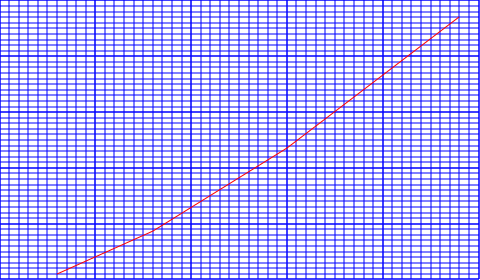

In [8]:
use plotters::prelude::*;

// Figure : log10(accessibles) contre la taille k du taquin. Les valeurs sont
// recalculees ici (u128) pour que la figure reste liee a la cellule precedente.
// Sans texte (feature `ttf` desactivee pour eviter la dependance systeme
// fontconfig) : la grille porte les graduations, la legende est en markdown.
// Le SVG est emis en image/svg+xml (pas de <div> HTML) : un SVG enrobe dans du
// HTML ne s'affiche pas dans le rendu GitHub du carnet (forme signalee sur #26613).
{
    fn log10_accessibles(k: u32) -> f64 {
        let mut r: u128 = 1;
        for i in 2..=(k as u128) { r *= i; }
        ((r / 2) as f64).log10()
    }
    let data: Vec<(f64, f64)> = [3u32, 8, 15, 24].iter()
        .map(|&k| (k as f64, log10_accessibles(k))).collect();
    let mut svg = String::new();
    {
        let root = SVGBackend::with_string(&mut svg, (480, 280)).into_drawing_area();
        let mut chart = ChartBuilder::on(&root)
            .build_cartesian_2d(0f64..25f64, 0f64..25f64)?;
        chart
            .configure_mesh()
            .bold_line_style(BLUE)
            .light_line_style(BLUE)
            .draw()?;
        chart.draw_series(LineSeries::new(data.clone(), RED))?;
    }
    println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);
};

### Lecture de la figure

Axe horizontal : taille `k` du taquin (3 a 24). Axe vertical : `log10` du nombre d'etats accessibles (0 a 25). La courbe monte de `log10(12) = 1.08` pour le 3-puzzle a `log10(7.76e24) = 24.89` pour le 24-puzzle : **pres de 24 ordres de grandeur en 4 points**. En echelle lineaire, la meme serie serait verticale des le troisieme point — c'est precisement pourquoi les manuels la tracent en log : seule l'echelle logarithmique laisse les petits taquins visibles a cote des grands.

## 4. Le probleme routier : Dijkstra et centralite

Deuxieme famille d'exemples : le **probleme de recherche de trajet**. L'etat est la ville courante, les actions sont les routes entrantes/sortantes, la transition change de ville, le test de but est la ville d'arrivee, et — nouveaute — le **cout** d'une action est la longueur en kilometres de la route.

> **Note de parite** : le jumeau C# resout le meme probleme sur un graphe different (13 villes, 41 arcs) ; les valeurs ci-dessous sont celles du jumeau Python : **11 villes, 14 aretes symetriques** (28 arcs orientation confondue).

In [9]:
// Graphe routier de France : 11 villes, 14 aretes symetriques.
// Ce `let` de donnees simples persiste d'une cellule a l'autre (evcxr garde
// les variables top-level de types simples) ; les fonctions, elles, ne
// persistent pas fiablement — les cellules suivantes restent autonomes.
let france_edges: Vec<(&'static str, &'static str, u32)> = vec![
    ("Paris", "Lyon", 465),
    ("Paris", "Lille", 225),
    ("Paris", "Strasbourg", 490),
    ("Paris", "Nantes", 385),
    ("Paris", "Bordeaux", 585),
    ("Lyon", "Marseille", 315),
    ("Lyon", "Grenoble", 105),
    ("Lyon", "Strasbourg", 490),
    ("Lille", "Strasbourg", 525),
    ("Bordeaux", "Toulouse", 245),
    ("Bordeaux", "Nantes", 345),
    ("Toulouse", "Montpellier", 245),
    ("Montpellier", "Marseille", 170),
    ("Marseille", "Nice", 200),
];
{
    use std::collections::HashMap;

    // Adjacence : chaque arete donne deux arcs (graphe non oriente).
    let mut adj: HashMap<&str, Vec<(&str, u32)>> = HashMap::new();
    for (a, b, d) in &france_edges {
        adj.entry(*a).or_default().push((b, *d));
        adj.entry(*b).or_default().push((a, *d));
    }
    let mut villes: Vec<&str> = Vec::new();
    for (a, b, _) in &france_edges {
        if !villes.contains(a) { villes.push(a); }
        if !villes.contains(b) { villes.push(b); }
    }
    let arcs: usize = adj.values().map(|v| v.len()).sum();
    println!("Villes : {}", villes.len());
    println!("Arcs (aretes x 2) : {}", arcs);
    println!("Facteur de branchement : {:.2}", arcs as f64 / villes.len() as f64);
    println!();
    println!("Voisins de Bordeaux : {:?}", adj["Bordeaux"]);
    println!("Voisins de Paris    : {:?}", adj["Paris"]);
};

Villes : 11


Arcs (aretes x 2) : 28


Facteur de branchement : 2.55


Voisins de Bordeaux : [("Paris", 585), ("Toulouse", 245), ("Nantes", 345)]


Voisins de Paris    : [("Lyon", 465), ("Lille", 225), ("Strasbourg", 490), ("Nantes", 385), ("Bordeaux", 585)]


### Lecture du resultat

L'adjacence se construit en une passe : chaque arete est ajoutee **deux fois** dans la `HashMap` (une par sens de parcours), d'ou 28 arcs pour 14 aretes. Le facteur de branchement du graphe routier est `28 / 11 = 2.55` — comparable au 2.67 du taquin, mais l'espace est minuscule (11 etats) : la difficulte des graphes routiers vient de la **structure des couts**, pas du cardinal.

In [10]:
{
    // graphe d'adjacence : ville -> liste de (voisin, distance en km)
    use std::collections::HashMap;
    let mut adj: HashMap<&str, Vec<(&str, u32)>> = HashMap::new();
    for (a, b, d) in &france_edges {
        // chaque route relie ses deux extremites (graphe non dirige)
        adj.entry(*a).or_default().push((b, *d));
        adj.entry(*b).or_default().push((a, *d));
    }
    // distance d'un arc direct entre a et b
    fn distance_directe(adj: &HashMap<&str, Vec<(&str, u32)>>, a: &str, b: &str) -> u32 {
        adj[a].iter().find(|(v, _)| *v == b).map(|(_, d)| *d).unwrap()
    }
    // longueur d'un chemin = somme des distances de ses arcs consecutifs
    fn longueur(adj: &HashMap<&str, Vec<(&str, u32)>>, chemin: &[&str]) -> u32 {
        chemin.windows(2).map(|p| distance_directe(adj, p[0], p[1])).sum()
    }

    // deux itineraires de Bordeaux a Strasbourg : via Paris (court) vs via le sud (long)
    let via_paris = ["Bordeaux", "Paris", "Strasbourg"];
    let via_sud = ["Bordeaux", "Toulouse", "Montpellier", "Marseille", "Lyon", "Strasbourg"];
    let d1 = longueur(&adj, &via_paris);
    let d2 = longueur(&adj, &via_sud);
    println!("Chemin 1 (via Paris) : {} etapes", via_paris.len() - 1);
    println!("  {}", via_paris.join(" -> "));
    println!("  Distance totale : {} km", d1);
    println!();
    println!("Chemin 2 (via le sud) : {} etapes", via_sud.len() - 1);
    println!("  {}", via_sud.join(" -> "));
    println!("  Distance totale : {} km", d2);
    println!();
    println!("Ecart : {} km en faveur du chemin via Paris ({} etapes contre {})",
        d2 - d1, via_paris.len() - 1, via_sud.len() - 1);
};

Chemin 1 (via Paris) : 2 etapes


  Bordeaux -> Paris -> Strasbourg


  Distance totale : 1075 km


Chemin 2 (via le sud) : 5 etapes


  Bordeaux -> Toulouse -> Montpellier -> Marseille -> Lyon -> Strasbourg


  Distance totale : 1465 km


Ecart : 390 km en faveur du chemin via Paris (2 etapes contre 5)


### Lecture du resultat

Les deux itineraires relient Bordeaux a Strasbourg, mais le parallele s'arrete la : **via Paris, 2 etapes et 1075 km ; via le sud, 5 etapes et 1465 km** — un ecart de 390 km. Moins d'etapes et moins de kilometres ne sont pas automatiquement lies (sur certains reseaux, le detour par un hub allonge le compte d'etapes mais raccourcit la distance) ; ici les deux criteres preferent le meme chemin. Le BFS du monde de l'aspirateur optimisait le **nombre d'actions** ; pour optimiser la **distance**, il faut un algorithme sensible aux couts — c'est le role de Dijkstra.

### L'organe natif : `petgraph::algo::dijkstra`

Le reflexe Rust n'est pas de reimplementer Dijkstra : la crate `petgraph` fournit le graphe (`Graph`) et l'algorithme (`petgraph::algo::dijkstra`). La fonction renvoie la distance minimale de la source a **chaque** sommet — pas le chemin lui-meme : l'itineraire se reconstruit en remontant depuis l'arrivee, sommet par sommet, en cherchant le voisin `v` tel que `dist(v) + poids(v -> courant) = dist(courant)`.

In [11]:
{
    use petgraph::Graph;
    use petgraph::Undirected;
    use petgraph::algo::dijkstra;
    use std::collections::HashMap;

    let mut g: Graph<&str, u32, Undirected> = Graph::new_undirected();
    let mut idx: HashMap<&str, petgraph::graph::NodeIndex> = HashMap::new();
    let mut villes: Vec<&str> = Vec::new();
    for (a, b, _) in &france_edges {
        if !villes.contains(a) { villes.push(a); }
        if !villes.contains(b) { villes.push(b); }
    }
    for v in &villes { idx.insert(v, g.add_node(v)); }
    for (a, b, d) in &france_edges { g.add_edge(idx[a], idx[b], *d); }

    let depart = idx["Bordeaux"];
    let arrivee = idx["Strasbourg"];
    let dists = dijkstra(&g, depart, None, |e| *e.weight());

    // Reconstruction de l'itineraire : depuis l'arrivee, remonter vers un
    // voisin v tel que dist(v) + poids(v, courant) = dist(courant).
    let mut chemin: Vec<&str> = vec!["Strasbourg"];
    let mut courant = arrivee;
    while courant != depart {
        for voisin in g.neighbors(courant) {
            if let Some(e) = g.find_edge(voisin, courant) {
                let w = *g.edge_weight(e).unwrap();
                if dists[&voisin] + w == dists[&courant] {
                    chemin.push(g[voisin]);
                    courant = voisin;
                    break;
                }
            }
        }
    }
    chemin.reverse();

    println!("Plus courte distance Bordeaux -> Strasbourg : {} km", dists[&arrivee]);
    println!("Itineraire : {}", chemin.join(" -> "));
    println!("Verification : {} sommets, {} aretes, facteur de branchement {:.2}",
        g.node_count(), g.edge_count(), g.edge_count() as f64 / g.node_count() as f64);
};

Plus courte distance Bordeaux -> Strasbourg : 1075 km


Itineraire : Bordeaux -> Paris -> Strasbourg


Verification : 11 sommets, 14 aretes, facteur de branchement 1.27


### Lecture du resultat

L'organe confirme le calcul manuel : **1075 km** par l'itineraire `Bordeaux -> Paris -> Strasbourg` — la meme reponse que la cellule precedente, obtenue cette fois par un algorithme qui n'a jamais vu les deux candidats a la main : Dijkstra a etendu sa frontiere depuis Bordeaux et provoque l'arrivee par le chemin le moins cher. C'est le modele de la **verification croisee** : le chemin construit a la main (cellule precedente) et le chemin calcule par l'organe (cette cellule) se recoupent, et la reconstruction par remontee des distances est la partie qui, en pratique, se bugge le plus — la boucle `while` ci-dessus en est l'implementation minimale.

### Centralite d'intermediabilite (betweenness)

Quelles villes portent le reseau ? La **centralite d'intermediabilite** d'une ville est la proportion de plus courts chemins (entre toutes les paires d'autres villes) qui passent par elle. Le jumeau Python appelle `networkx.betweenness_centrality` ; `petgraph` ne fournit **pas** cette mesure.

**Copie pedagogique declaree** (regle organ-first) : l'algorithme de Brandes (2001) est implante ici en une trentaine de lignes — un Dijkstra par source qui compte les plus courts chemins (`sigma`), memorise les predecesseurs, puis retro-propage les dependances. Motif : voir comment la mesure se calcule ; l'organe Python reste la reference du chiffre. La normalisation divise par `(n-1)(n-2) = 90` pour 11 villes (paires ordonnees).

In [12]:
{
    use std::cmp::Reverse;
    use std::collections::{BinaryHeap, HashMap, HashSet};

    let mut adj: HashMap<&str, Vec<(&str, u32)>> = HashMap::new();
    for (a, b, d) in &france_edges {
        adj.entry(*a).or_default().push((b, *d));
        adj.entry(*b).or_default().push((a, *d));
    }
    let mut villes: Vec<&str> = Vec::new();
    for (a, b, _) in &france_edges {
        if !villes.contains(a) { villes.push(a); }
        if !villes.contains(b) { villes.push(b); }
    }
    let n = villes.len();

    // Copie pedagogique declaree : Brandes (2001) sur graphe non oriente value.
    let mut cb: HashMap<&str, f64> = villes.iter().map(|v| (*v, 0.0)).collect();

    for &s in &villes {
        // Dijkstra depuis s : distances, nombre de plus courts chemins (sigma),
        // predecesseurs, ordre de finalisation (pour la retro-propagation).
        let mut dist: HashMap<&str, u32> = HashMap::new();
        let mut sigma: HashMap<&str, u64> = villes.iter().map(|v| (*v, 0)).collect();
        let mut preds: HashMap<&str, Vec<&str>> = HashMap::new();
        let mut ordre: Vec<&str> = Vec::new();
        let mut finis: HashSet<&str> = HashSet::new();
        let mut tas: BinaryHeap<Reverse<(u32, &str)>> = BinaryHeap::new();
        dist.insert(s, 0);
        *sigma.get_mut(&s).unwrap() = 1;
        tas.push(Reverse((0, s)));
        while let Some(Reverse((d, v))) = tas.pop() {
            if d > dist[v] { continue; }         // entree perimee du tas
            if !finis.insert(v) { continue; }     // sommet deja finalise
            ordre.push(v);
            for &(w, poids) in &adj[v] {
                let nouveau = d + poids;
                let dw = *dist.get(w).unwrap_or(&u32::MAX);
                if nouveau < dw {
                    dist.insert(w, nouveau);
                    *sigma.get_mut(&w).unwrap() = sigma[&v];
                    preds.insert(w, vec![v]);
                    tas.push(Reverse((nouveau, w)));
                } else if nouveau == dw {
                    *sigma.get_mut(&w).unwrap() += sigma[&v];
                    preds.get_mut(&w).unwrap().push(v);
                }
            }
        }
        // Retro-propagation des dependances, dans l'ordre inverse de finalisation
        let mut delta: HashMap<&str, f64> = villes.iter().map(|v| (*v, 0.0)).collect();
        for &w in ordre.iter().rev() {
            for &p in preds.get(&w).unwrap_or(&Vec::new()) {
                let part = sigma[&p] as f64 / sigma[&w] as f64 * (1.0 + delta[&w]);
                *delta.get_mut(&p).unwrap() += part;
            }
            if w != s { *cb.get_mut(&w).unwrap() += delta[&w]; }
        }
    }

    // Normalisation (paires ordonnees) : diviser par (n-1)(n-2) = 90 ici.
    let mut classement: Vec<(&str, f64)> = cb.into_iter().collect();
    classement.sort_by(|a, b| b.1.partial_cmp(&a.1).unwrap());
    println!("Centralite d'intermediabilite (normalisee, n = {}) :", n);
    for (i, (ville, score)) in classement.iter().take(5).enumerate() {
        println!("  {:<2} {:<12} {:.3}", i + 1, ville, score / ((n - 1) * (n - 2)) as f64);
    }
};

Centralite d'intermediabilite (normalisee, n = 11) :


  1  Marseille    0.422


  2  Lyon         0.422


  3  Paris        0.267


  4  Montpellier  0.244


  5  Toulouse     0.178


### Lecture du resultat

Le podium est **Lyon et Marseille (0.422)**, devant **Paris (0.267)** — identiques aux valeurs du jumeau Python (`networkx.betweenness_centrality`). Lyon doit sa place a sa position de charniere : tous les plus courts chemins entre le sud-est (Grenoble, Nice) et le nord (Paris, Lille, Strasbourg) y transitent. Marseille, porte du Languedoc, joue le meme role pour les flux Toulouse/Montpellier vers l'est. Paris, malgre ses 5 routes, est un cul-de-sac geographique : les plus courts chemins du reseau l'evitent au profit de l'axe Lyon-Strasbourg. La copie pedagogique recoupe l'organe de reference : le chiffre est le meme, seule la voie d'acces change.

### La carte du reseau et de l'itineraire optimal

La figure suivante place les 11 villes a leurs coordonnees geographiques (longitude/latitude normalisees, comme dans le jumeau Python). Les aretes sont en gris ; l'itineraire optimal Bordeaux-Strasbourg (recalcule ici par un Dijkstra maison) est en **rouge epais** ; Bordeaux en **jaune** (depart), Strasbourg en **vert** (arrivee), les autres villes en bleu. Sans texte dans la figure (feature `ttf` desactivee) : la legende, c'est cette phrase.

Itineraire optimal trace en rouge : Bordeaux -> Paris -> Strasbourg (1075 km)


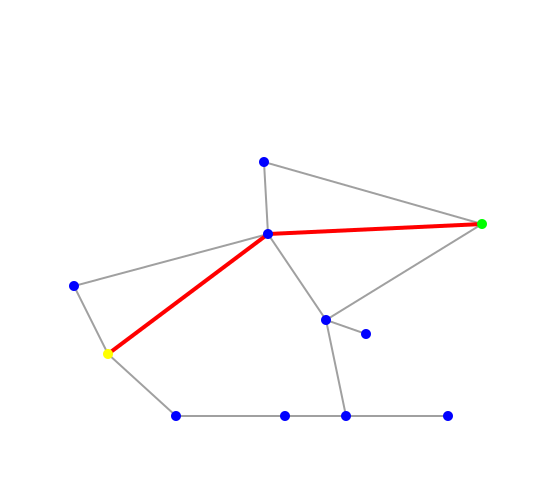

In [13]:
use plotters::prelude::*;
use std::cmp::Reverse;
use std::collections::{BinaryHeap, HashMap};

// Coordonnees (longitude, latitude) normalisees — identiques au jumeau Python.
let pos: Vec<(&str, f64, f64)> = vec![
    ("Paris", 2.35, 6.3),
    ("Lyon", 3.2, 4.5),
    ("Marseille", 3.5, 2.5),
    ("Lille", 2.3, 7.8),
    ("Strasbourg", 5.5, 6.5),
    ("Bordeaux", 0.0, 3.8),
    ("Toulouse", 1.0, 2.5),
    ("Montpellier", 2.6, 2.5),
    ("Nantes", -0.5, 5.2),
    ("Nice", 5.0, 2.5),
    ("Grenoble", 3.8, 4.2),
];
{
    // Adjacence + Dijkstra maison (BinaryHeap) pour recalculer l'itineraire.
    let mut adj: HashMap<&str, Vec<(&str, u32)>> = HashMap::new();
    for (a, b, d) in &france_edges {
        adj.entry(*a).or_default().push((b, *d));
        adj.entry(*b).or_default().push((a, *d));
    }
    let mut dist: HashMap<&str, u32> = HashMap::new();
    let mut tas: BinaryHeap<Reverse<(u32, &str)>> = BinaryHeap::new();
    dist.insert("Bordeaux", 0);
    tas.push(Reverse((0, "Bordeaux")));
    while let Some(Reverse((d, v))) = tas.pop() {
        if d > dist[v] { continue; }
        for &(w, poids) in &adj[v] {
            if d + poids < *dist.get(w).unwrap_or(&u32::MAX) {
                dist.insert(w, d + poids);
                tas.push(Reverse((d + poids, w)));
            }
        }
    }
    let mut chemin: Vec<&str> = vec!["Strasbourg"];
    let mut courant = "Strasbourg";
    while courant != "Bordeaux" {
        for &(w, poids) in &adj[courant] {
            if dist[w] + poids == dist[courant] {
                chemin.push(w);
                courant = w;
                break;
            }
        }
    }
    chemin.reverse();
    println!("Itineraire optimal trace en rouge : {} ({} km)", chemin.join(" -> "), dist["Strasbourg"]);

    // Projection (longitude, latitude) -> pixels. lon dans [-1, 6], lat dans [2, 8].
    let to_px = |lon: f64, lat: f64| -> (i32, i32) {
        let x = 40.0 + (lon + 1.0) * 68.0;
        let y = 440.0 - (lat - 2.0) * 48.0;
        (x.round() as i32, y.round() as i32)
    };
    let xy = |nom: &str| -> (f64, f64) {
        let &(_, lon, lat) = pos.iter().find(|p| p.0 == nom).unwrap();
        (lon, lat)
    };

    let mut svg = String::new();
    {
        let root = SVGBackend::with_string(&mut svg, (560, 480)).into_drawing_area();
        root.fill(&WHITE)?;
        // Aretes en gris
        for (a, b, _) in &france_edges {
            let (x1, y1) = xy(a);
            let (x2, y2) = xy(b);
            let (p1, p2) = (to_px(x1, y1), to_px(x2, y2));
            root.draw(&PathElement::new(vec![p1, p2], ShapeStyle::from(&RGBColor(160, 160, 160)).stroke_width(2)))?;
        }
        // Itineraire optimal en rouge epais
        let points: Vec<(i32, i32)> = chemin.iter().map(|v| { let (lo, la) = xy(v); to_px(lo, la) }).collect();
        root.draw(&PathElement::new(points, ShapeStyle::from(&RED).stroke_width(4)))?;
        // Villes : jaune = depart, vert = arrivee, bleu = autres
        for &(nom, lon, lat) in &pos {
            let p = to_px(lon, lat);
            let style = if nom == "Bordeaux" { ShapeStyle::from(&YELLOW).filled() }
                else if nom == "Strasbourg" { ShapeStyle::from(&GREEN).filled() }
                else { ShapeStyle::from(&BLUE).filled() };
            root.draw(&Circle::new(p, 5, style))?;
        }
        root.present()?;
    }
    println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);
};

### Lecture de la figure

L'itineraire rouge remonte du Sud-Ouest vers **Paris** puis file a l'Est vers Strasbourg : 2 etapes, 1075 km. Le chemin du sud (gris, via Toulouse-Montpellier-Marseille-Lyon) dessine un arc de cercle complet autour du Massif central — visiblement plus long. La carte rend aussi la centralite de Lyon lisible a l'oeil : la ville est au croisement des axes Nord-Sud (Paris-Marseille) et Est-Ouest (Strasbourg-Grenoble), tandis que Paris, extreme ouest-nord du reseau, ne sert que les flux qui y vont vraiment.

## 5. Exemples guides : missionnaires-cannibales et labyrinthe

### Les missionnaires et les cannibales

Trois missionnaires et trois cannibales doivent traverser une riviere dans une barque a deux places. Si, sur une rive, les cannibales strictement plus nombreux que les missionnaires, le drame se produit. L'etat est le triplet `(missionnaires a gauche, cannibales a gauche, cote du bateau)` ; un **etat invalide** n'est jamais visite — le filtrage se fait dans la generation des actions.

In [14]:
{
    // (S, s0, A, T, G) pour les missionnaires et les cannibales.
    #[derive(Clone, PartialEq, Eq, Hash, Debug)]
    struct RiveState {
        m_g: u32,     // missionnaires sur la rive gauche
        c_g: u32,     // cannibales sur la rive gauche
        bateau: char, // 'G' ou 'D'
    }

    fn rive_valide(m: u32, c: u32) -> bool { m == 0 || m >= c }

    fn etat_valide(s: &RiveState) -> bool {
        rive_valide(s.m_g, s.c_g) && rive_valide(3 - s.m_g, 3 - s.c_g)
    }

    fn transition_me(s: &RiveState, m: u32, c: u32) -> RiveState {
        let mut n = s.clone();
        if s.bateau == 'G' {
            n.m_g -= m; n.c_g -= c; n.bateau = 'D';
        } else {
            n.m_g += m; n.c_g += c; n.bateau = 'G';
        }
        n
    }

    // Actions : (m, c) passagers embarques, 1 <= m + c <= 2. Seules les actions
    // dont le chargement est possible ET l'etat cible valide sont proposees.
    fn actions_possibles(s: &RiveState) -> Vec<(u32, u32)> {
        let mut res = Vec::new();
        for m in 0..=2u32 {
            for c in 0..=2u32 {
                if 1 <= m + c && m + c <= 2 {
                    let chargeable = if s.bateau == 'G' { m <= s.m_g && c <= s.c_g }
                                     else { m <= 3 - s.m_g && c <= 3 - s.c_g };
                    if chargeable && etat_valide(&transition_me(s, m, c)) {
                        res.push((m, c));
                    }
                }
            }
        }
        res
    }

    // Taille de l'espace d'etats : les triplets valides parmi 4 x 4 x 2
    let mut compteur = 0;
    for m in 0..=3u32 { for c in 0..=3u32 { for b in ['G', 'D'] {
        if etat_valide(&RiveState { m_g: m, c_g: c, bateau: b }) { compteur += 1; }
    }}}
    println!("Etats valides : {} sur 32 triplets possibles", compteur);

    let initial = RiveState { m_g: 3, c_g: 3, bateau: 'G' };
    println!("Actions depuis l'etat initial : {:?}", actions_possibles(&initial));
    println!();

    // BFS : file FIFO + ensemble des etats vus
    use std::collections::{HashSet, VecDeque};
    let mut vus: HashSet<RiveState> = HashSet::new();
    let mut file: VecDeque<(RiveState, Vec<(u32, u32)>)> = VecDeque::new();
    vus.insert(initial.clone());
    file.push_back((initial.clone(), Vec::new()));
    let mut solution: Option<Vec<(u32, u32)>> = None;
    while let Some((etat, chemin)) = file.pop_front() {
        if etat.m_g == 0 && etat.c_g == 0 {
            solution = Some(chemin);
            break;
        }
        for (m, c) in actions_possibles(&etat) {
            let suivant = transition_me(&etat, m, c);
            if vus.insert(suivant.clone()) {
                let mut ch = chemin.clone();
                ch.push((m, c));
                file.push_back((suivant, ch));
            }
        }
    }

    fn affiche_rive(m: u32, c: u32) -> String { format!("{}M {}C", m, c) }

    println!("{:<6}{:<14}{:<12}{:<12}{}", "Etape", "Action (M,C)", "Rive gauche", "Rive droite", "Bateau");
    let mut etat = initial;
    println!("{:<6}{:<14}{:<12}{:<12}{}", "init", "-", affiche_rive(etat.m_g, etat.c_g), affiche_rive(3 - etat.m_g, 3 - etat.c_g), etat.bateau);
    match solution {
        Some(chemin) => {
            for (i, &(m, c)) in chemin.iter().enumerate() {
                etat = transition_me(&etat, m, c);
                let sens = if etat.bateau == 'D' { "->" } else { "<-" };
                println!("{:<6}{:<14}{:<12}{:<12}{}", i + 1, format!("({}, {}) {}", m, c, sens),
                    affiche_rive(etat.m_g, etat.c_g), affiche_rive(3 - etat.m_g, 3 - etat.c_g), etat.bateau);
            }
            println!();
            println!("Solution en {} traversees.", chemin.len());
        }
        None => println!("Aucune solution."),
    }
};

Etats valides : 20 sur 32 triplets possibles


Actions depuis l'etat initial : [(0, 1), (0, 2), (1, 1)]


Etape Action (M,C)  Rive gauche Rive droite Bateau


init  -             3M 3C       0M 0C       G


1     (0, 2) ->     3M 1C       0M 2C       D


2     (0, 1) <-     3M 2C       0M 1C       G


... (6 outputs left out)

9     (0, 2) ->     0M 1C       3M 2C       D


10    (0, 1) <-     0M 2C       3M 1C       G


11    (0, 2) ->     0M 0C       3M 3C       D


Solution en 11 traversees.


### Lecture du resultat

L'espace brut compte 32 triplets (4 x 4 x 2), mais seuls **20 etats sont valides** : les 12 autres mettent des missionnaires en danger sur une rive. Depuis l'etat initial, seules trois actions survivent au filtre — embarquer **(0,1)**, **(0,2)** ou **(1,1)** : embarquer des missionnaires sans cannibales les laisserait en inferiorite a gauche. La solution compte **11 traversees** : la barque fait systématiquement l'aller-retour en emportant au maximum deux personnes, et un seul etat (voyage solitaire) ramene le bateau. Le BFS ne visite que des etats valides — le filtre dans `actions_possibles` remplace le post-filtrage du jumeau Python.

### Le labyrinthe

Dernier exemple guide : un labyrinthe en grille ASCII, ou `S` marque le depart, `E` la sortie et `#` un mur. L'etat est le couple `(ligne, colonne)` ; les actions sont les quatre directions. Trois cas : une sortie voisine du depart, une sortie inatteignable, et la grille de l'enonce.

In [15]:
{
    #[derive(Clone, PartialEq, Eq, Hash, Debug)]
    struct Pos { l: i32, c: i32 }

    struct MazeProblem {
        grille: Vec<Vec<char>>,
        depart: Pos,
        sortie: Pos,
    }

    const DIRECTIONS: [(&str, i32, i32); 4] = [
        ("Haut", -1, 0),
        ("Bas", 1, 0),
        ("Gauche", 0, -1),
        ("Droite", 0, 1),
    ];

    impl MazeProblem {
        fn nouvelle(grille: &[&str]) -> Option<MazeProblem> {
            let g: Vec<Vec<char>> = grille.iter().map(|l| l.chars().collect()).collect();
            let (mut depart, mut sortie) = (None, None);
            for (l, ligne) in g.iter().enumerate() {
                for (c, &ch) in ligne.iter().enumerate() {
                    if ch == 'S' { depart = Some(Pos { l: l as i32, c: c as i32 }); }
                    if ch == 'E' { sortie = Some(Pos { l: l as i32, c: c as i32 }); }
                }
            }
            match (depart, sortie) {
                (Some(d), Some(s)) => Some(MazeProblem { grille: g, depart: d, sortie: s }),
                _ => None,
            }
        }
        fn franchissable(&self, l: i32, c: i32) -> bool {
            l >= 0 && c >= 0
                && (l as usize) < self.grille.len()
                && (c as usize) < self.grille[0].len()
                && self.grille[l as usize][c as usize] != '#'
        }
        fn actions_de(&self, p: &Pos) -> Vec<&'static str> {
            let mut res = Vec::new();
            for (nom, dl, dc) in DIRECTIONS {
                if self.franchissable(p.l + dl, p.c + dc) { res.push(nom); }
            }
            res
        }
        fn cases_libres(&self) -> usize {
            self.grille.iter().map(|l| l.iter().filter(|&&ch| ch != '#').count()).sum()
        }
    }

    fn bouger(p: &Pos, action: &str) -> Pos {
        for (nom, dl, dc) in DIRECTIONS {
            if nom == action {
                return Pos { l: p.l + dl, c: p.c + dc };
            }
        }
        p.clone()
    }

    // BFS : plus court chemin du depart a la sortie, en nombre d'actions
    fn bfs_chemin(m: &MazeProblem) -> Option<Vec<&'static str>> {
        use std::collections::{HashSet, VecDeque};
        let mut vus: HashSet<Pos> = HashSet::new();
        let mut file: VecDeque<(Pos, Vec<&'static str>)> = VecDeque::new();
        vus.insert(m.depart.clone());
        file.push_back((m.depart.clone(), Vec::new()));
        while let Some((p, chemin)) = file.pop_front() {
            if p == m.sortie { return Some(chemin); }
            for a in m.actions_de(&p) {
                let suivant = bouger(&p, a);
                if vus.insert(suivant.clone()) {
                    let mut ch = chemin.clone();
                    ch.push(a);
                    file.push_back((suivant, ch));
                }
            }
        }
        None
    }

    fn analyser(titre: &str, grille: &[&str]) {
        println!("=== {} ===", titre);
        match MazeProblem::nouvelle(grille) {
            Some(m) => {
                println!("Labyrinthe {}x{} | depart ({}, {}) | sortie ({}, {}) | cases accessibles : {}",
                    m.grille.len(), m.grille[0].len(),
                    m.depart.l, m.depart.c, m.sortie.l, m.sortie.c, m.cases_libres());
                println!("Actions depuis le depart : {:?}", m.actions_de(&m.depart));
                match bfs_chemin(&m) {
                    Some(chemin) => println!("Solution trouvee en {} etapes : {}", chemin.len(), chemin.join(" -> ")),
                    None => println!("Aucune solution : la sortie est inatteignable."),
                }
            }
            None => println!("Grille invalide : il faut exactement un 'S' et un 'E'."),
        }
        println!();
    }

    analyser("Cas limite : sortie voisine du depart", &["SE"]);
    analyser("Cas limite : sortie inatteignable", &["S#E"]);
    analyser("Cas nominal : grille de l'enonce", &["S.#....", ".#.#.#.", ".#...#.", ".###.#.", ".....#E"]);
};

=== Cas limite : sortie voisine du depart ===


Labyrinthe 1x2 | depart (0, 0) | sortie (0, 1) | cases accessibles : 2


Actions depuis le depart : ["Droite"]


Solution trouvee en 1 etapes : Droite


=== Cas limite : sortie inatteignable ===


Labyrinthe 1x3 | depart (0, 0) | sortie (0, 2) | cases accessibles : 2


... (2 outputs left out)

=== Cas nominal : grille de l'enonce ===


Labyrinthe 5x7 | depart (0, 0) | sortie (4, 6) | cases accessibles : 24


Actions depuis le depart : ["Bas", "Droite"]


Solution trouvee en 18 etapes : Bas -> Bas -> Bas -> Bas -> Droite -> Droite -> Droite -> Droite -> Haut -> Haut -> Haut -> Haut -> Droite -> Droite -> Bas -> Bas -> Bas -> Bas


### Lecture du resultat

Les deux cas limites calibrent le solveur : `SE` (sortie voisine) se resout en **1 etape** (`Droite`), et `S#E` (mur entre les deux) n'a **aucune solution** — le BFS epuise les 2 cases accessibles sans atteindre la sortie. La grille 5x7 de l'enonce offre 24 cases accessibles et une solution en **18 etapes** : 4 fois `Bas`, 4 fois `Droite`, 4 fois `Haut`, 2 fois `Droite`, puis 4 fois `Bas`. Remarquez la sequence `Haut` au milieu du chemin : le plus court chemin n'est pas monotone — il faut revenir sur ses pas pour contourner le mur central, et le chemin repasse par des cases deja traversees. C'est normal : le critere est le nombre d'actions, pas le nombre de cases distinctes.

## 6. Exercices

Trois exercices, du diagnostic (parite du taquin) a la modelisation complete (cruches d'eau). Chaque stub s'execute sans erreur : le notebook reste valide meme non complete.

### Exercice 4 — La parite du taquin

**Objectif** : ecrire `nombre_inversions` (compter les paires mal ordonnees en ignorant la case vide) puis `est_soluble` (sur grille de largeur impaire, un etat est atteignable depuis le but si et seulement si le nombre d'inversions est pair), et verifier sur l'etat initial du carnet.

**Indice** : pour `nombre_inversions`, un double `for` sur les indices `i < j` avec `etat[i] > etat[j]` et `etat[j] != 0` suffit. Pour `est_soluble`, largeur 3 = impaire : la parite seule decide.

In [16]:
// EXERCICE 4 : parite du taquin
// TODO etudiant :
// 1. Completer nombre_inversions (double boucle sur les paires i < j)
// 2. Completer est_soluble (largeur impaire : atteignable si et seulement si inversions pair)
// 3. Verifier sur l'etat initial [7, 2, 4, 5, 0, 6, 8, 3, 1]
{
    // Indice : ignorer la case vide (0) dans le comptage des inversions.
    fn nombre_inversions(etat: &[u8; 9]) -> usize {
        // Etape 1 : pour chaque paire (i, j) avec i < j, compter si etat[i] > etat[j] > 0
        let _ = etat;
        0
    }

    fn est_soluble(etat: &[u8; 9]) -> bool {
        // Etape 2 : grille de largeur 3 (impaire) -> inversions pair si et seulement si soluble
        let _ = etat;
        false
    }

    let exemple: [u8; 9] = [2, 1, 3, 4, 5, 6, 7, 8, 0];
    println!("Exercice a completer : nombre_inversions([2, 1, 3, ...]) = {}", nombre_inversions(&exemple));
    println!("Exercice a completer : determiner est_soluble([7, 2, 4, 5, 0, 6, 8, 3, 1])");
};

Exercice a completer : nombre_inversions([2, 1, 3, ...]) = 0


Exercice a completer : determiner est_soluble([7, 2, 4, 5, 0, 6, 8, 3, 1])


### Exercice 5 — Le labyrinthe avec cle

**Objectif** : etendre le labyrinthe avec une cle `K` a ramasser et une porte `D` qui ne s'ouvre qu'avec la cle. L'etat devient le triplet `(ligne, colonne, a_la_cle)`.

**Indice** : la grille de test est `K.S.. / ####. / E.D..` — la cle est au nord-ouest, la porte ferme le couloir sud vers `E`. L'espace d'etats compte (cases libres) x 2 etats de cle. Question bonus : pourquoi le chemin optimal repasse-t-il par des cases deja traversees ?

In [17]:
// EXERCICE 5 : labyrinthe avec cle 'K' et porte 'D'
// TODO etudiant :
// 1. Completer taille_espace_cle (cases hors murs x 2, avec ou sans la cle)
// 2. Completer resoudre_avec_cle (BFS sur l'etat (ligne, colonne, a_la_cle))
{
    fn taille_espace_cle(grille: &[&str]) -> usize {
        // Etape 1 : compter les cases != '#' et multiplier par 2 (cle possedee ou non)
        let _ = grille;
        0
    }

    fn resoudre_avec_cle(grille: &[&str]) -> Vec<String> {
        // Etape 2 : BFS depuis (ligne de 'S', colonne de 'S', false) ;
        // Indice : marcher sur 'K' passe a_la_cle a true ; 'D' est franchissable
        // seulement si a_la_cle ; le but est la case 'E'.
        let _ = grille;
        Vec::new()
    }

    let key_grid = ["K.S..", "####.", "E.D.."];
    println!("Exercice a completer : {} etats possibles", taille_espace_cle(&key_grid));
    println!("Exercice a completer : {} etapes", resoudre_avec_cle(&key_grid).len());
};

Exercice a completer : 0 etats possibles


Exercice a completer : 0 etapes


### Exercice 6 — Les cruches d'eau

**Objectif** : modeliser deux cruches (capacites 3 L et 5 L) et mesurer exactement 4 L. Les actions sont remplir une cruche, la vider, ou transvaser jusqu'a debordement/epuisement ; le but est qu'une cruche contienne exactement le volume cible.

**Indice** : l'etat est le couple `(contenu_a, contenu_b)` — l'espace compte `(3+1) x (5+1) = 24` etats au plus. Question bonus : avec des cruches de 2 L et 4 L, pourquoi 3 L est-il inatteignable ? (pensez aux multiples de 2).

In [18]:
// EXERCICE 6 : les cruches d'eau
// TODO etudiant :
// 1. Completer taille_espace_cruches ((cap_a + 1) * (cap_b + 1))
// 2. Completer bfs_cruches (BFS depuis (0, 0) ; but : une cruche == cible)
{
    fn taille_espace_cruches(cap_a: u32, cap_b: u32) -> usize {
        // Etape 1 : chaque cruche contient de 0 a sa capacite
        let _ = (cap_a, cap_b);
        0
    }

    fn bfs_cruches(cap_a: u32, cap_b: u32, cible: u32) -> usize {
        // Etape 2 : actions = RemplirA, RemplirB, ViderA, ViderB, VerserAB, VerserBA
        // Indice : le transvasement s'arrete au debordement du recepteur ou a
        // l'epuisement du donneur ; le but est contenu_a == cible ou contenu_b == cible.
        let _ = (cap_a, cap_b, cible);
        0
    }

    println!("Exercice a completer : cruches 3/5 -> {} etats possibles", taille_espace_cruches(3, 5));
    println!("Exercice a completer : BFS vers 4 L : {} actions", bfs_cruches(3, 5, 4));
};

Exercice a completer : cruches 3/5 -> 0 etats possibles


Exercice a completer : BFS vers 4 L : 0 actions


## A retenir

- **Le trait remplace la classe abstraite** : le 5-uplet (S, s0, A, T, G) devient `trait SearchProblem` avec un type associe `State` — chaque probleme choisit sa representation d'etat (struct, tableau, tuple).
- **Le BFS tient en dix lignes de std** : `VecDeque` (file FIFO) + `HashSet` (etats vus) ; l'insertion dans l'ensemble sert de garde anti-doublon.
- **`petgraph` est l'organe natif des graphes** : `Graph` + `petgraph::algo::dijkstra` remplacent l'implementation maison ; la betweenness, absente de la crate, reste une copie pedagogique declaree (Brandes), recoupee contre `networkx`.
- **`u128` pour les factorielles** : 21! deborde `u64`, et un debordement Rust panique en debug — choisir le type AVANT d'ecrire la boucle.
- **evcxr : `:dep` en tete, cellules autonomes** : les items (traits, fonctions) ne persistent pas fiablement ; chaque cellule de ce carnet est un bloc `{ ... };` autonome, seules les donnees simples (`france_edges`) persistent.
- **La verification croisee** : chemin manuel vs Dijkstra (1075 km des deux cotes), Brandes vs networkx (Lyon/Marseille 0.422) — deux voies d'acces independantes au meme chiffre.

## Verifiez votre comprehension

1. **Pourquoi chaque cellule de ce carnet redefinit-elle le trait `SearchProblem` dans son propre bloc, au lieu de le definir une fois pour toutes ?**

   <details>
   <summary>Reponse</summary>

   Le kernel evcxr compile cellule par cellule et ne persiste pas fiablement les items (traits, fonctions, types) au-dela de leur cellule de definition — seules les variables top-level de types simples survivent (comme `france_edges`). Enclos dans un bloc `{ ... };`, chaque cellule est autonome : elle recompile et s'execute seule, ce qui rend aussi le carnet robuste au re-execution partielle.
   </details>

2. **Pourquoi la cellule factorielle utilise-t-elle `u128` et que se passerait-il avec `u64` sur le 24-puzzle ?**

   <details>
   <summary>Reponse</summary>

   `20!` (environ `2.43e18`) est le dernier factoriel representable en `u64` (borne `2^64 - 1` environ `1.8e19`) ; `21!` deborde. En Rust, un debordement arithmetique en compilation debug **panique** avec `attempt to multiply with overflow` au lieu de s'enrouler en silence : la cellule s'arreterait avec une erreur au lieu d'afficher un resultat faux — comportement plus sur, mais qu'il faut anticiper en choisissant `u128` (borne environ `3.4e38`, ou `25!` tient largement).
   </details>

3. **La centralite classe Lyon et Marseille (0.422) devant Paris (0.267), alors que Paris a plus de routes. Pourquoi ?**

   <details>
   <summary>Reponse</summary>

   La betweenness compte les **plus courts chemins qui traversent** un sommet, pas ses aretes. Lyon est la charniere des flux nord-sud (Paris-Marseille) et est-ouest (Strasbourg-Grenoble) : presque tout transit sud-est vers nord y passe. Paris, extremite nord-ouest du reseau, n'est sur le chemin que des paires dont il est une extremite ou un relais optimal (comme Bordeaux-Strasbourg) — ses 5 aretes en font un hub de degre eleve, pas un point de passage.
   </details>

## Pour aller plus loin

- [Search-01 Python](Search-01-StateSpace.ipynb) — la theorie complete : formalisation, exemples fondateurs, pieges classiques.
- [Search-01 C#](Search-01-StateSpace-CSharp.ipynb) — le meme probleme dans le jumeau .NET (sur un graphe de France different : 13 villes, 41 arcs).
- [Search-02 Uninformed](Search-02-Uninformed.ipynb) — la suite de la serie : BFS, DFS et Dijkstra en tant qu'algorithmes generiques non informes.
- [La crate petgraph (docs.rs)](https://docs.rs/petgraph) — la documentation de l'organe : `Graph`, `algo::dijkstra`, `algo::astar`, et les parcours.
- Brandes (2001), *A Faster Algorithm for Betweenness Centrality* — l'algorithme de la copie pedagogique.